# DSCI 552 – Homework 4

*Name:* Nithya Prasasthani Eeri

*GitHub Username:* Nithya0605-eeri

*USC ID:* 9182042369

In [187]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import statsmodels.api as sm
from pathlib import Path

print("All libraries imported successfully!")
print("Current directory:", Path.cwd())

All libraries imported successfully!
Current directory: /Users/enithyaprasasthani/Documents/DSCI552_HW4


In [188]:
from pathlib import Path

data_path = Path("data")/"AReM"

print("Dataset exists:", data_path.exists())
print("Dataset location:", data_path)

Dataset exists: True
Dataset location: data/AReM


In [189]:
#Verify AReM dataset

from pathlib import Path

data_path = Path("data")/"AReM"

activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

total_files = 0

for activity in activities:
    folder = data_path / activity
    files = list(folder.glob("dataset*.csv"))

    print(f"{activity}: {len(files)} files")
    total_files += len(files)

print("--------------------")
print("Total instances:", total_files)

bending1: 7 files
bending2: 6 files
cycling: 15 files
lying: 15 files
sitting: 15 files
standing: 15 files
walking: 15 files
--------------------
Total instances: 88


In [190]:
#Split training and testing datasets

train_files = []
test_files = []

for activity in activities:
    folder = data_path / activity
    files = sorted(
        folder.glob("dataset*.csv"),
        key=lambda x: int(x.stem.replace("dataset", ""))
    )

    if activity in ["bending1", "bending2"]:
        test_numbers = [1, 2]
    else:
        test_numbers = [1, 2, 3]

    for file in files:
        number = int(file.stem.replace("dataset", ""))

        if number in test_numbers:
            test_files.append((activity, file))
        else:
            train_files.append((activity, file))

print("Training instances:", len(train_files))
print("Testing instances:", len(test_files))
print("Total instances:", len(train_files) + len(test_files))

Training instances: 69
Testing instances: 19
Total instances: 88


In [191]:
#Inspect a time-series dataset

import pandas as pd

sample_file = train_files[0][1]

print("Activity:", train_files[0][0])
print("File:", sample_file.name)

print("\nFirst 5 rows:")
with open(sample_file, "r") as f:
    for _ in range(5):
        print(f.readline().strip())

Activity: bending1
File: dataset3.csv

First 5 rows:
# Task: bending1
# Frequency (Hz): 20
# Clock (millisecond): 250
# Duration (seconds): 120
# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23


In [192]:
#Load and clean one dataset

import pandas as pd

column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

df = pd.read_csv(
    sample_file,
    comment="#",
    header=None,
    names=column_names,
    sep=r"\s*,\s*",
    engine="python"
)

# Convert columns to numeric values
for col in column_names:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (480, 7)

First 5 rows:


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,42.00,0.71,21.25,0.43,30.00,0.00
1,250,41.50,0.50,20.25,1.48,31.25,1.09
2,500,41.50,0.50,14.25,1.92,33.00,0.00
3,750,40.75,0.83,15.75,0.43,33.00,0.00
4,1000,40.00,0.71,20.00,2.74,32.75,0.43



Missing values:
time         0
avg_rss12    0
var_rss12    0
avg_rss13    0
var_rss13    0
avg_rss23    0
var_rss23    0
dtype: int64


In [193]:
# Step 3C: Extract time-domain features

import numpy as np
import pandas as pd

sensor_columns = column_names[1:]

def extract_features(df):
    features = {}

    for i, col in enumerate(sensor_columns, start=1):
        values = df[col].dropna()

        features[f"min{i}"] = values.min()
        features[f"max{i}"] = values.max()
        features[f"mean{i}"] = values.mean()
        features[f"median{i}"] = values.median()
        features[f"std{i}"] = values.std()
        features[f"q1_{i}"] = values.quantile(0.25)
        features[f"q3_{i}"] = values.quantile(0.75)

    return features

# Extract features from the sample dataset
sample_features = extract_features(df)

features_df = pd.DataFrame([sample_features])

print("Number of features:", features_df.shape[1])
display(features_df)

Number of features: 42


,min1,max1,mean1,median1,std1,q1_1,q3_1,min2,max2,mean2,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
0,35.0,47.4,43.9545,44.33,1.558835,43.0,45.0,0.0,1.7,0.42625,...,1.999604,35.3625,36.5,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94


In [194]:
#Load and clean all AReM datasets

import pandas as pd
import re

def load_dataset(file):
    rows = []

    with open(file, "r") as f:
        for line in f:
            line = line.strip()

            # Skip comments and empty lines
            if not line or line.startswith("#"):
                continue

            # Split comma-separated or whitespace-separated data
            values = re.split(r"[,\s]+", line)

            # Keep only rows with exactly 7 columns
            if len(values) != 7:
                print(f"Checking malformed row in {file.name}: {line}")
                continue

            rows.append(values)

    df = pd.DataFrame(rows, columns=column_names)

    for col in column_names:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df


def create_feature_dataset(file_list):
    rows = []

    for activity, file in file_list:
        df = load_dataset(file)

        features = extract_features(df)
        features["activity"] = activity
        features["filename"] = file.name

        rows.append(features)

    return pd.DataFrame(rows)


train_features = create_feature_dataset(train_files)
test_features = create_feature_dataset(test_files)

all_features = pd.concat(
    [train_features, test_features],
    ignore_index=True
)

print("Training dataset shape:", train_features.shape)
print("Testing dataset shape:", test_features.shape)
print("Complete dataset shape:", all_features.shape)

print("Total missing values:",
      all_features.isnull().sum().sum())

display(all_features.head())

Checking malformed row in dataset9.csv: 119750,38.33,0.94,15.25,2.17,20.33,1.25,
Checking malformed row in dataset14.csv: 119750,34.00,2.12,24.50,1.80,22.25,2.59,
Training dataset shape: (69, 44)
Testing dataset shape: (19, 44)
Complete dataset shape: (88, 44)
Total missing values: 0


,min1,max1,mean1,median1,std1,q1_1,q3_1,min2,max2,mean2,...,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6,activity,filename
0,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,dataset3.csv
1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,dataset4.csv
2,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,dataset5.csv
3,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,dataset6.csv
4,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,dataset7.csv


In [195]:
#Fix trailing commas and verify row counts

import re
import pandas as pd

def load_dataset(file):
    rows = []

    with open(file, "r") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            # Remove extra commas at the end of rows
            line = line.rstrip(",")

            values = re.split(r"[,\s]+", line)

            if len(values) != 7:
                raise ValueError(
                    f"Malformed row in {file.name}: {line}"
                )

            rows.append(values)

    df = pd.DataFrame(rows, columns=column_names)
    df = df.apply(pd.to_numeric, errors="raise")

    return df


# Verify all 88 datasets
row_counts = []

for activity, file in train_files + test_files:
    df_check = load_dataset(file)
    row_counts.append(len(df_check))

print("Total datasets:", len(row_counts))
print("Datasets with 480 rows:",
      sum(count == 480 for count in row_counts))
print("Datasets with incorrect row counts:",
      sum(count != 480 for count in row_counts))

# Recreate feature datasets using corrected loader
train_features = create_feature_dataset(train_files)
test_features = create_feature_dataset(test_files)

all_features = pd.concat(
    [train_features, test_features],
    ignore_index=True
)

print("Complete feature dataset:", all_features.shape)
print("Missing values:", all_features.isnull().sum().sum())

Total datasets: 88
Datasets with 480 rows: 87
Datasets with incorrect row counts: 1
Complete feature dataset: (88, 44)
Missing values: 0


In [196]:
#Identify datasets with incorrect row counts

for activity, file in train_files + test_files:
    df_check = load_dataset(file)

    if len(df_check) != 480:
        print("Activity:", activity)
        print("File:", file.name)
        print("Number of rows:", len(df_check))
        print("Expected rows: 480")

Activity: sitting
File: dataset8.csv
Number of rows: 479
Expected rows: 480


In [197]:
#Inspect the dataset with 479 rows

problem_file = data_path / "sitting" / "dataset8.csv"

with open(problem_file, "r") as f:
    lines = [
        line.strip()
        for line in f
        if line.strip() and not line.startswith("#")
    ]

print("Total data lines:", len(lines))

print("\nFirst 3 rows:")
for line in lines[:3]:
    print(line)

print("\nLast 5 rows:")
for line in lines[-5:]:
    print(line)

print("\nTime values:")
df_problem = load_dataset(problem_file)
print("First time:", df_problem["time"].iloc[0])
print("Last time:", df_problem["time"].iloc[-1])

Total data lines: 479

First 3 rows:
0,44.00,0.71,18.75,0.43,7.75,1.30
250,44.00,0.00,18.50,0.50,8.67,0.47
500,43.75,0.83,18.00,0.00,9.67,0.94

Last 5 rows:
118750,42.25,0.43,18.00,0.00,16.50,1.12
119000,42.00,0.00,18.00,0.00,16.00,0.82
119250,42.50,0.50,18.00,0.00,15.25,0.43
119500,42.50,0.50,18.25,0.43,16.00,1.22
119750,42.25,0.43,20.00,0.71,19.00,1.00

Time values:
First time: 0
Last time: 119750


In [198]:
#Find missing timestamps

import numpy as np

df_problem = load_dataset(problem_file)

expected_times = np.arange(0, 120000, 250)

actual_times = df_problem["time"].to_numpy()

missing_times = np.setdiff1d(
    expected_times,
    actual_times
)

print("Expected observations:", len(expected_times))
print("Actual observations:", len(actual_times))
print("Missing timestamps:", missing_times)

print("\nDuplicate timestamps:",
      df_problem["time"].duplicated().sum())

Expected observations: 480
Actual observations: 479
Missing timestamps: [13500]

Duplicate timestamps: 0


In [199]:
#Fix missing observation using interpolation

def load_dataset_fixed(file):
    df = load_dataset(file)

    # Repair the missing timestamp in sitting/dataset8.csv
    if file.parent.name == "sitting" and file.name == "dataset8.csv":

        expected_times = np.arange(0, 120000, 250)

        df = df.set_index("time")
        df = df.reindex(expected_times)

        # Interpolate missing sensor measurements
        df = df.interpolate(method="linear")

        df.index.name = "time"
        df = df.reset_index()

    return df


# Verify the repaired dataset
fixed_df = load_dataset_fixed(problem_file)

print("Rows after fixing:", len(fixed_df))
print("Missing values:", fixed_df.isnull().sum().sum())

print("\nRepaired observation:")
display(fixed_df[fixed_df["time"] == 13500])

Rows after fixing: 480
Missing values: 0

Repaired observation:


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
54,13500,42.0,0.0,17.56,2.69,17.27,3.42


In [200]:
#Rebuild features using cleaned datasets

def create_feature_dataset_fixed(file_list):
    rows = []

    for activity, file in file_list:
        df = load_dataset_fixed(file)

        features = extract_features(df)
        features["activity"] = activity
        features["filename"] = file.name

        rows.append(features)

    return pd.DataFrame(rows)


train_features = create_feature_dataset_fixed(train_files)
test_features = create_feature_dataset_fixed(test_files)

all_features = pd.concat(
    [train_features, test_features],
    ignore_index=True
)

# Verify all datasets have 480 observations
row_counts = [
    len(load_dataset_fixed(file))
    for activity, file in train_files + test_files
]

print("Training dataset:", train_features.shape)
print("Testing dataset:", test_features.shape)
print("Complete dataset:", all_features.shape)
print("Datasets with 480 rows:", sum(n == 480 for n in row_counts))
print("Missing values:", all_features.isnull().sum().sum())

Training dataset: (69, 44)
Testing dataset: (19, 44)
Complete dataset: (88, 44)
Datasets with 480 rows: 88
Missing values: 0


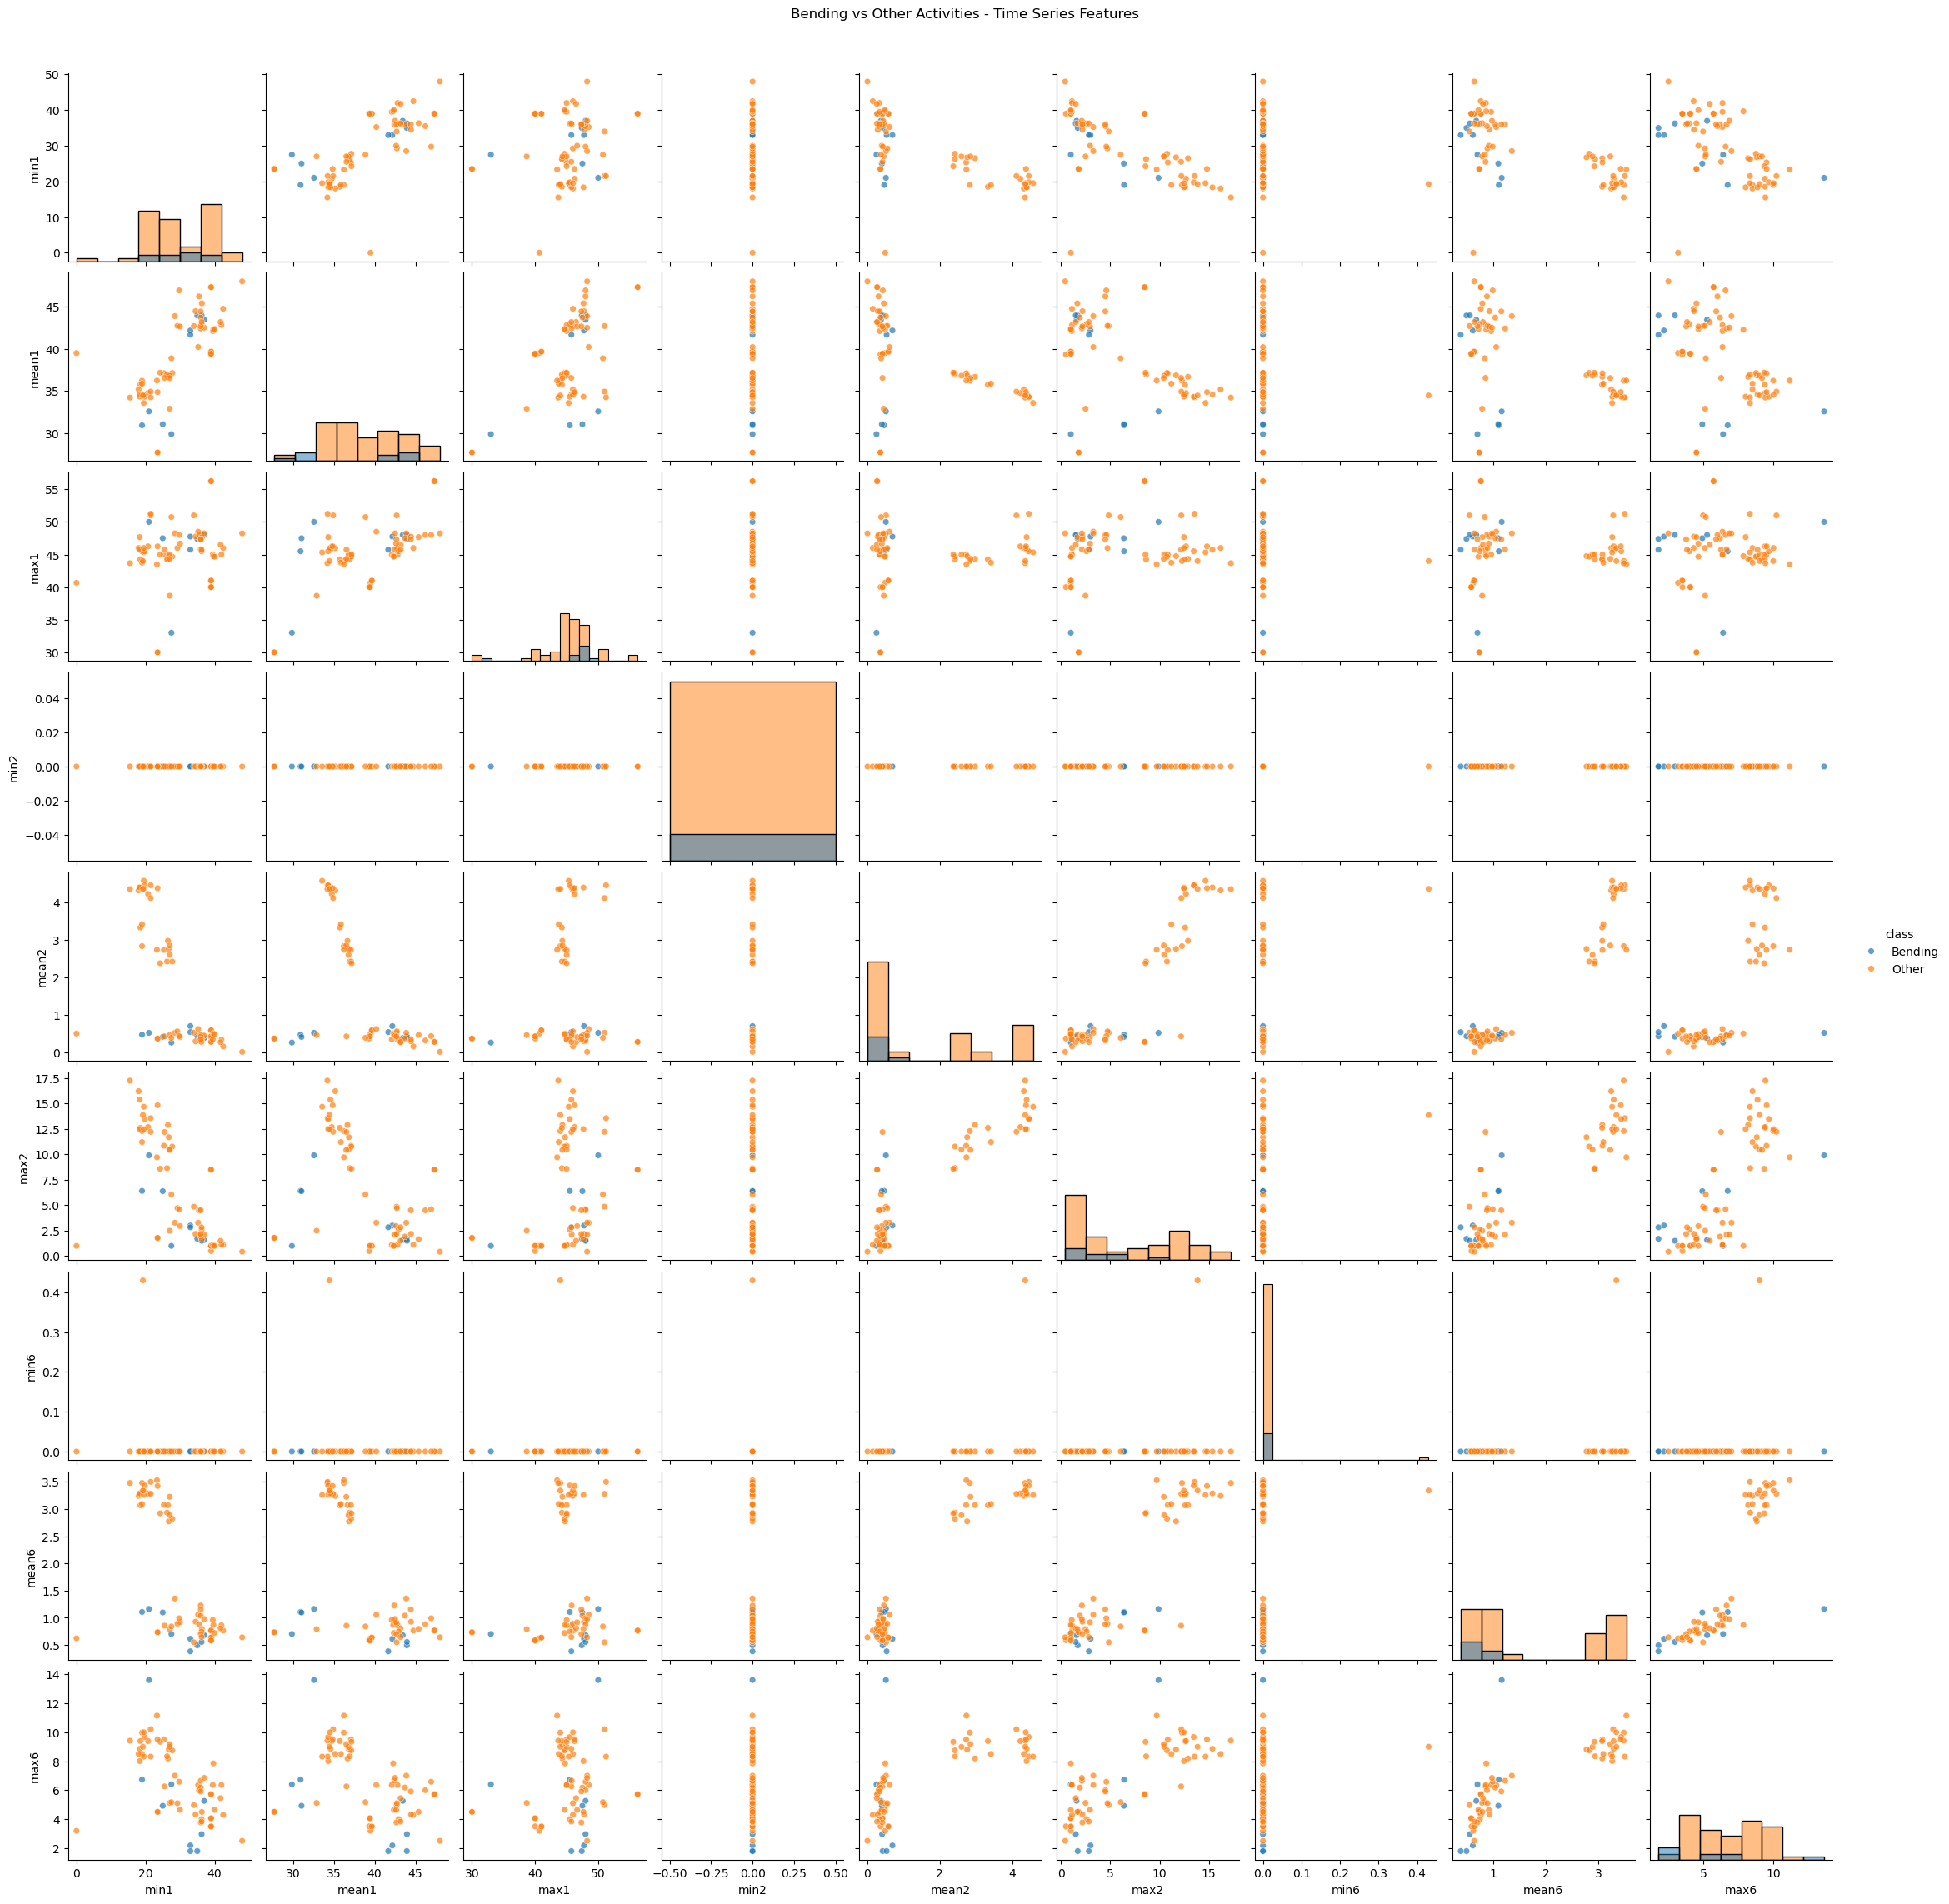

In [201]:
# Homework 4 - Question 2(a)i
# Scatter plots: Bending vs Other Activities

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create binary classification labels
plot_df = train_features.copy()

plot_df["class"] = plot_df["activity"].apply(
    lambda x: "Bending" if x in ["bending1", "bending2"]
    else "Other"
)

# Features from time series 1, 2, and 6
selected_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

# Create scatter plot matrix
sns.pairplot(
    plot_df,
    vars=selected_features,
    hue="class",
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 30}
)

plt.suptitle(
    "Bending vs Other Activities - Time Series Features",
    y=1.02
)

plt.show()

In [202]:
# Homework 4 - Question 2(a)ii
# Split each time series into 2 equal parts

def extract_split_features(df):
    features = {}

    for i, col in enumerate(sensor_columns, start=1):
        values = df[col].to_numpy()

        parts = np.array_split(values, 2)

        for j, part in enumerate(parts, start=1):
            features[f"min{i}_part{j}"] = np.min(part)
            features[f"mean{i}_part{j}"] = np.mean(part)
            features[f"max{i}_part{j}"] = np.max(part)

    return features


# Extract features from training instances only
split_rows = []

for activity, file in train_files:
    df_split = load_dataset_fixed(file)

    features = extract_split_features(df_split)

    features["class"] = (
        "Bending"
        if activity in ["bending1", "bending2"]
        else "Other"
    )

    split_rows.append(features)

split_features_df = pd.DataFrame(split_rows)

print("Dataset shape:", split_features_df.shape)
print("Number of instances:", len(split_features_df))
print("Number of numerical features:",
      split_features_df.shape[1] - 1)

display(split_features_df.head())

Dataset shape: (69, 37)
Number of instances: 69
Number of numerical features: 36


,min1_part1,mean1_part1,max1_part1,min1_part2,mean1_part2,max1_part2,min2_part1,mean2_part1,max2_part1,min2_part2,...,min5_part2,mean5_part2,max5_part2,min6_part1,mean6_part1,max6_part1,min6_part2,mean6_part2,max6_part2,class
0,36.50,44.057167,46.50,35.00,43.851833,47.40,0.0,0.381042,1.50,0.0,...,29.00,34.883375,38.25,0.0,0.598250,1.79,0.0,0.388333,1.50,Bending
1,33.75,43.278875,47.75,33.00,41.080750,46.00,0.0,0.673292,3.00,0.0,...,20.00,30.965708,38.50,0.0,0.640958,1.53,0.0,0.586083,2.18,Bending
2,33.00,41.621208,45.75,39.25,41.734917,43.67,0.0,0.623083,2.83,0.0,...,26.00,29.635833,36.00,0.0,0.419083,1.79,0.0,0.347500,1.50,Bending
3,39.00,44.117042,48.00,37.00,42.792875,46.50,0.0,0.250042,1.30,0.0,...,8.00,22.850875,26.00,0.0,0.815417,5.26,0.0,0.543875,4.06,Bending
4,36.67,43.486208,45.00,36.25,44.452042,48.00,0.0,0.378667,1.30,0.0,...,13.75,21.882042,26.00,0.0,0.524875,2.28,0.0,0.585750,2.96,Bending


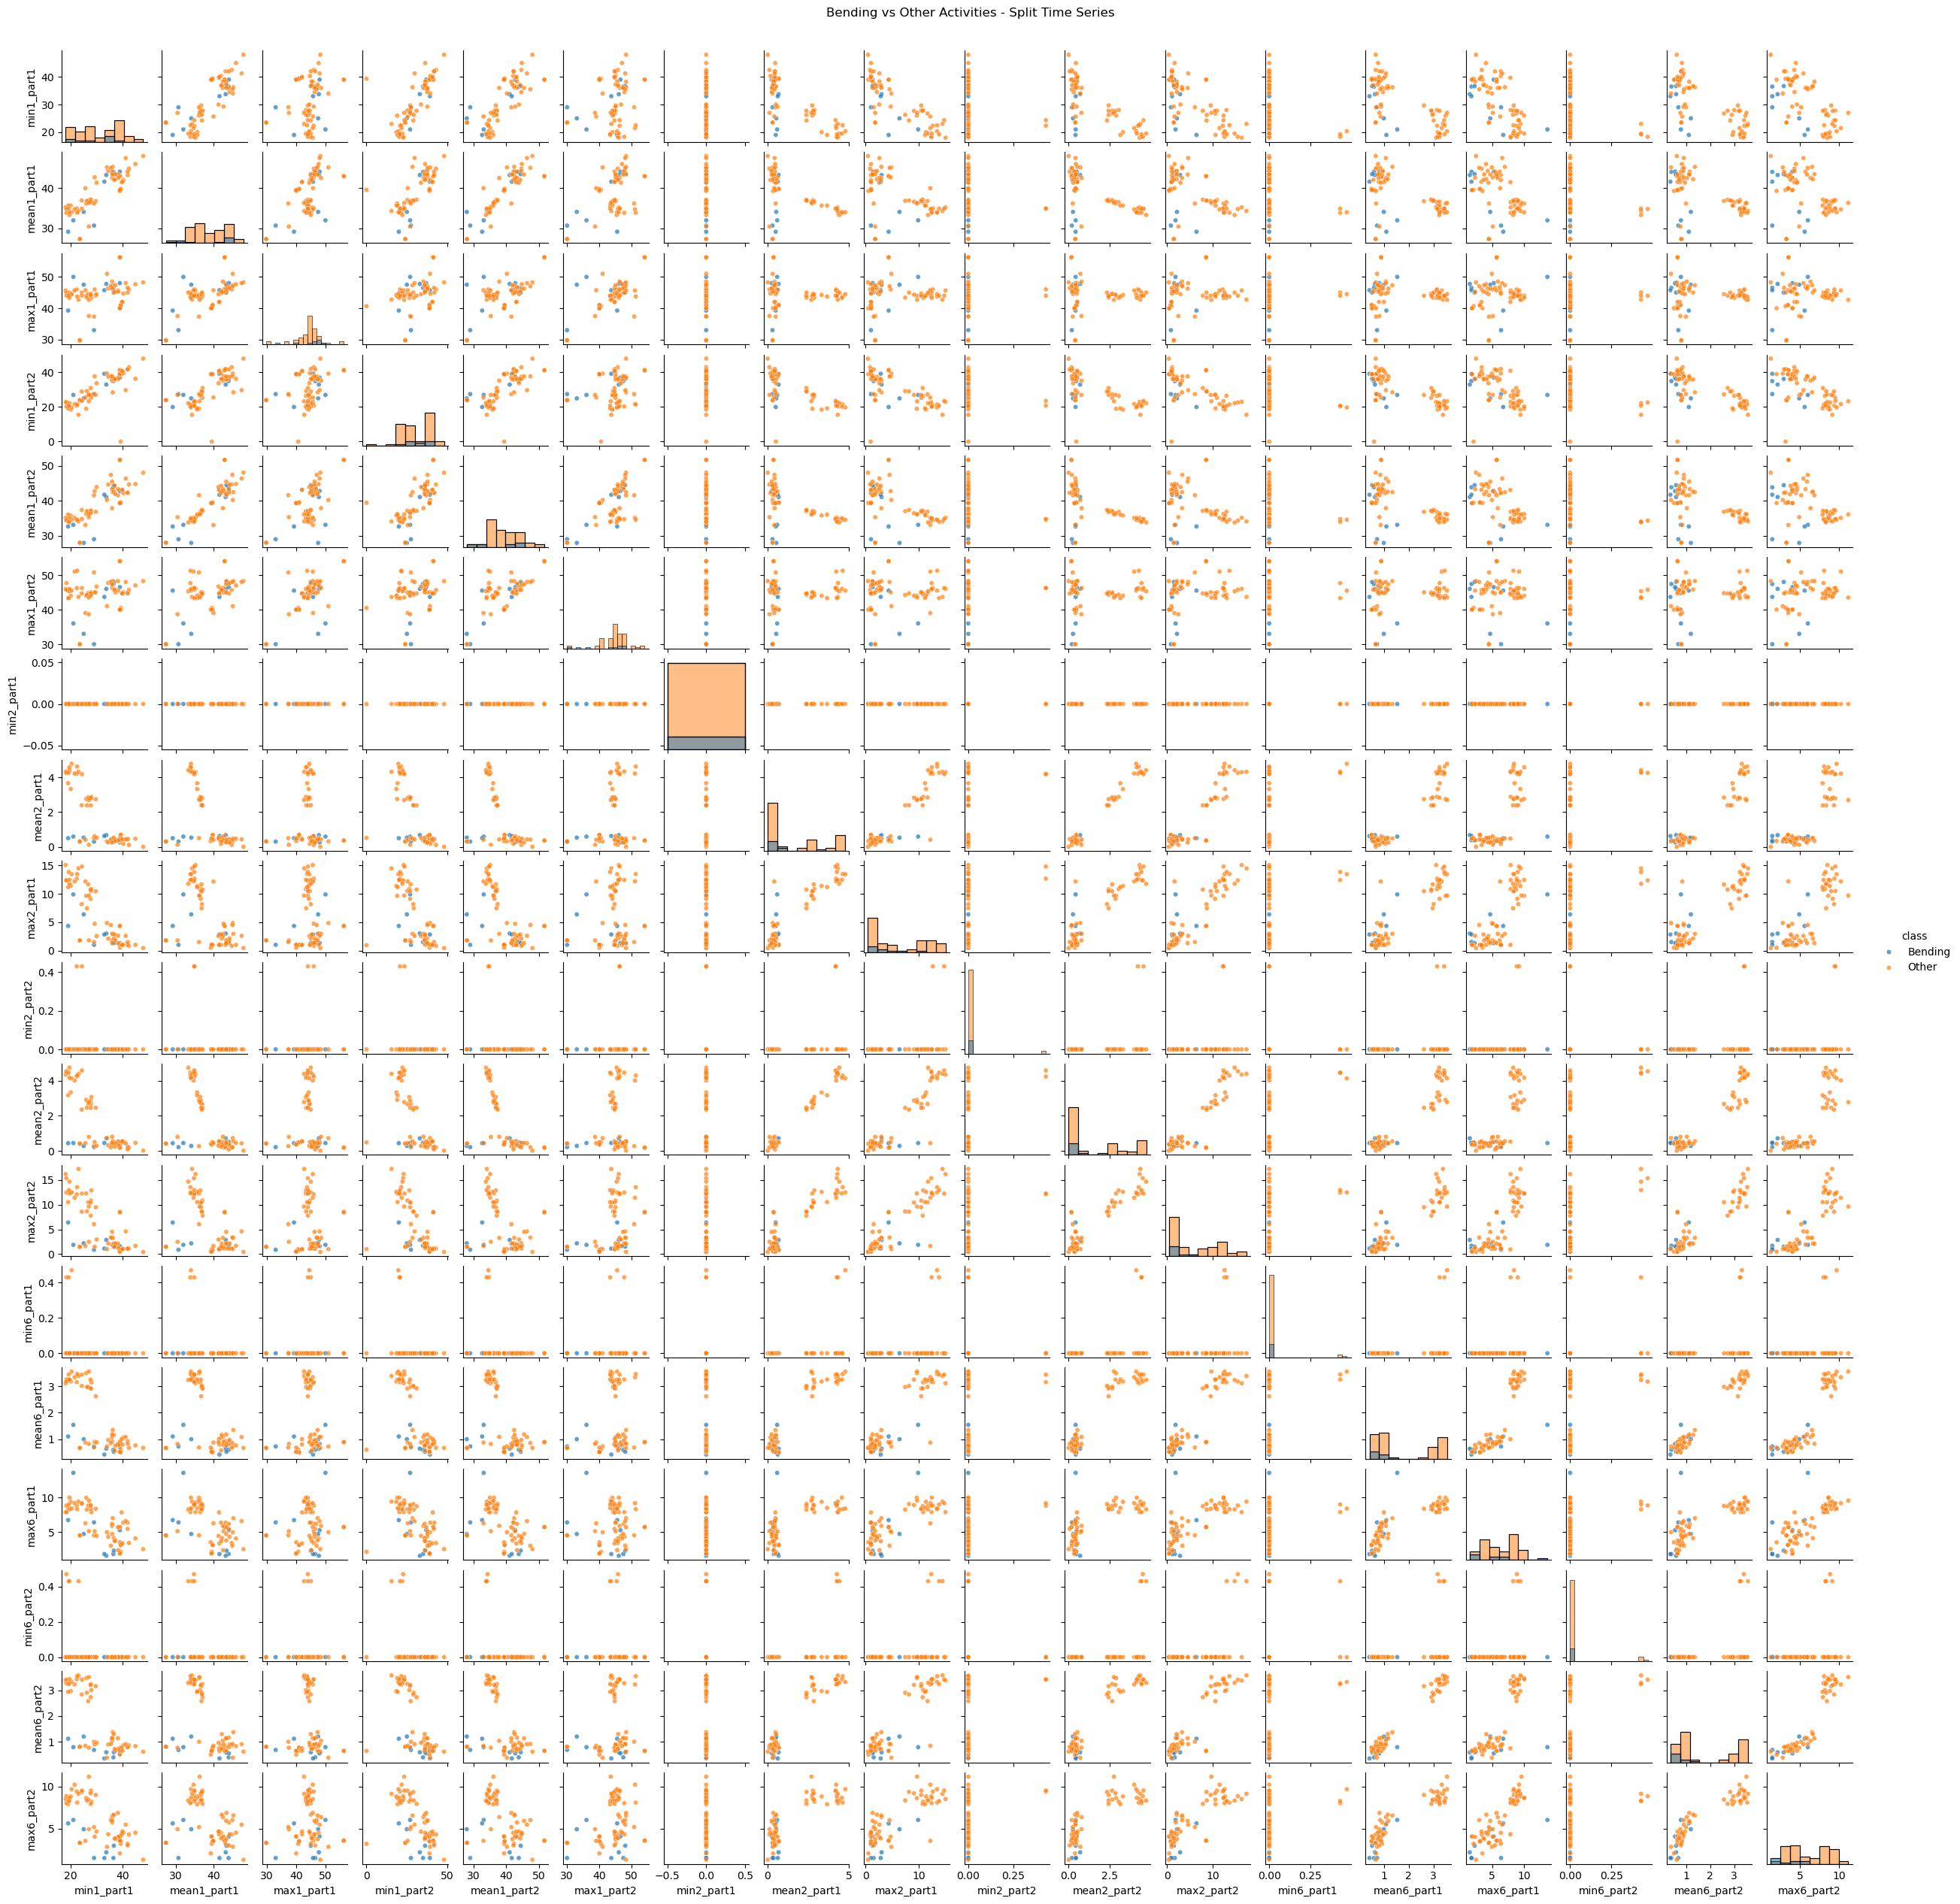

In [203]:
# Homework 4 - Question 2(a)ii
# Scatter plots after splitting time series into 2 parts

import seaborn as sns
import matplotlib.pyplot as plt

selected_split_features = [
    "min1_part1", "mean1_part1", "max1_part1",
    "min1_part2", "mean1_part2", "max1_part2",
    "min2_part1", "mean2_part1", "max2_part1",
    "min2_part2", "mean2_part2", "max2_part2",
    "min6_part1", "mean6_part1", "max6_part1",
    "min6_part2", "mean6_part2", "max6_part2"
]

g = sns.pairplot(
    split_features_df,
    vars=selected_split_features,
    hue="class",
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 20},
    height=1.4
)

g.fig.suptitle(
    "Bending vs Other Activities - Split Time Series",
    y=1.01
)

plt.show()

Question 2(a)ii – Comparison of Scatter Plots

After splitting each time series into two equal parts, I extracted the minimum, mean, and maximum features from both halves of time series 1, 2, and 6.

Compared with the original scatter plots, the split time series provide more detailed information about how the sensor measurements change over time. Some feature combinations appear to show differences between bending and other activities, although the classes still overlap in several plots.

Overall, splitting the time series may help distinguish the activities, but the scatter plots alone do not establish a major improvement in classification performance. Logistic regression and cross-validation will help evaluate this further.

In [204]:
# Homework 4 - Question 2(a)iii
# Prepare binary classification labels

import numpy as np
import pandas as pd

y_train = train_features["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

y_test = test_features["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

print("Training instances:", len(y_train))
print("Testing instances:", len(y_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training instances: 69
Testing instances: 19

Training class distribution:
activity
0    60
1     9
Name: count, dtype: int64

Testing class distribution:
activity
0    15
1     4
Name: count, dtype: int64


In [205]:
# Homework 4 - Question 2(a)iii
# Extract features for l = 1 to 20

import numpy as np
import pandas as pd

def extract_features_l(df, l):
    features = {}

    for i, col in enumerate(sensor_columns, start=1):
        values = df[col].to_numpy()

        segments = np.array_split(values, l)

        for j, segment in enumerate(segments, start=1):
            features[f"min{i}_{j}"] = np.min(segment)
            features[f"max{i}_{j}"] = np.max(segment)
            features[f"mean{i}_{j}"] = np.mean(segment)
            features[f"median{i}_{j}"] = np.median(segment)
            features[f"std{i}_{j}"] = np.std(segment, ddof=1)
            features[f"q1_{i}_{j}"] = np.percentile(segment, 25)
            features[f"q3_{i}_{j}"] = np.percentile(segment, 75)

    return features


def create_features_l(file_list, l):
    rows = []

    for activity, file in file_list:
        df = load_dataset_fixed(file)
        features = extract_features_l(df, l)
        rows.append(features)

    return pd.DataFrame(rows)


# Test feature extraction for l = 1, 2, 5, 10, 20
for l in [1, 2, 5, 10, 20]:
    X = create_features_l(train_files, l)

    print(
        f"l = {l}: "
        f"{X.shape[0]} instances, "
        f"{X.shape[1]} features"
    )

l = 1: 69 instances, 42 features
l = 2: 69 instances, 84 features
l = 5: 69 instances, 210 features
l = 10: 69 instances, 420 features
l = 20: 69 instances, 840 features


In [206]:
# Homework 4 - Question 2(a)iii
# Set up stratified 5-fold cross-validation

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic regression without L2 regularization
logistic_model = LogisticRegression(
    penalty=None,
    max_iter=1000,
    solver="lbfgs"
)

# Verify the class distribution in each fold
for fold, (train_idx, val_idx) in enumerate(
    cv.split(
        create_features_l(train_files, 1),
        y_train
    ),
    start=1
):
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    print(f"Fold {fold}")
    print("  Training:", y_fold_train.value_counts().to_dict())
    print("  Validation:", y_fold_val.value_counts().to_dict())

Fold 1
  Training: {0: 48, 1: 7}
  Validation: {0: 12, 1: 2}
Fold 2
  Training: {0: 48, 1: 7}
  Validation: {0: 12, 1: 2}
Fold 3
  Training: {0: 48, 1: 7}
  Validation: {0: 12, 1: 2}
Fold 4
  Training: {0: 48, 1: 7}
  Validation: {0: 12, 1: 2}
Fold 5
  Training: {0: 48, 1: 8}
  Validation: {0: 12, 1: 1}


In [207]:
# Homework 4 - Question 2(a)iii
# Preliminary cross-validation test

from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

results = []

# Small test before full search
l_values = [1, 2]
p_values = [5, 10]

for l in l_values:
    X_train_l = create_features_l(train_files, l)

    for p in p_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(
                estimator=LogisticRegression(
                    penalty=None,
                    solver="lbfgs",
                    max_iter=500
                ),
                n_features_to_select=p,
                step=0.2
            )),
            ("classifier", LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=500
            ))
        ])

        scores = cross_val_score(
            model,
            X_train_l,
            y_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=1
        )

        results.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores.mean(),
            "CV Error": 1 - scores.mean()
        })

        print(
            f"l={l}, p={p}, "
            f"CV Accuracy={scores.mean():.4f}"
        )

results_df = pd.DataFrame(results)

print("\nCross-validation results:")
display(results_df)

l=1, p=5, CV Accuracy=0.9571
l=1, p=10, CV Accuracy=0.9714
l=2, p=5, CV Accuracy=0.9429
l=2, p=10, CV Accuracy=0.9571

Cross-validation results:


,l,p,CV Accuracy,CV Error
0,1,5,0.957143,0.042857
1,1,10,0.971429,0.028571
2,2,5,0.942857,0.057143
3,2,10,0.957143,0.042857


In [208]:
# Homework 4 - Question 2(a)iii
# Cross-validation search for l = 1 to 20

from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import pandas as pd
import warnings

warnings.filterwarnings(
    "ignore",
    category=UserWarning
)

full_results = []

# Search all 20 segment values
for l in range(1, 21):

    X_train_l = create_features_l(train_files, l)

    # Candidate numbers of selected features
    for p in [5, 10, 15, 20]:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(
                estimator=LogisticRegression(
                    penalty=None,
                    solver="lbfgs",
                    max_iter=500
                ),
                n_features_to_select=p,
                step=0.2
            )),
            ("classifier", LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=500
            ))
        ])

        scores = cross_val_score(
            model,
            X_train_l,
            y_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=1
        )

        full_results.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores.mean(),
            "CV Error": 1 - scores.mean()
        })

    print(f"Completed l = {l}/20")

full_results_df = pd.DataFrame(full_results)

# Find best combination
best_row = full_results_df.sort_values(
    ["CV Error", "l", "p"]
).iloc[0]

best_l = int(best_row["l"])
best_p = int(best_row["p"])

print("\nBest l:", best_l)
print("Best p:", best_p)
print("Best CV Accuracy:", best_row["CV Accuracy"])
print("Best CV Error:", best_row["CV Error"])

display(
    full_results_df.sort_values(
        "CV Error"
    ).head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20

Best l: 20
Best p: 10
Best CV Accuracy: 0.9857142857142858
Best CV Error: 0.014285714285714235


,l,p,CV Accuracy,CV Error
77,20,10,0.985714,0.014286
39,10,20,0.971429,0.028571
1,1,10,0.971429,0.028571
2,1,15,0.971429,0.028571
74,19,15,0.971429,0.028571
73,19,10,0.971429,0.028571
78,20,15,0.971429,0.028571
23,6,20,0.971429,0.028571
14,4,15,0.971429,0.028571
47,12,20,0.957143,0.042857


In [209]:
# Homework 4 - Question 2(a)iii
# Fit final logistic regression model with RFE

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

X_train_best = create_features_l(train_files, best_l)

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=500
        ),
        n_features_to_select=best_p,
        step=0.2
    )),
    ("classifier", LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=500
    ))
])

final_model.fit(X_train_best, y_train)

selected_features = X_train_best.columns[
    final_model.named_steps["rfe"].support_
]

print("Best l:", best_l)
print("Best p:", best_p)
print("\nSelected features:")

for feature in selected_features:
    print(feature)

print("\nTraining accuracy:",
      final_model.score(X_train_best, y_train))

Best l: 20
Best p: 10

Selected features:
std3_9
min3_16
std3_16
min5_3
std5_3
q1_5_3
std5_16
min5_18
std5_18
std5_19

Training accuracy: 1.0


Training Accuracy: 1.0

Confusion Matrix:
[[60  0]
 [ 0  9]]


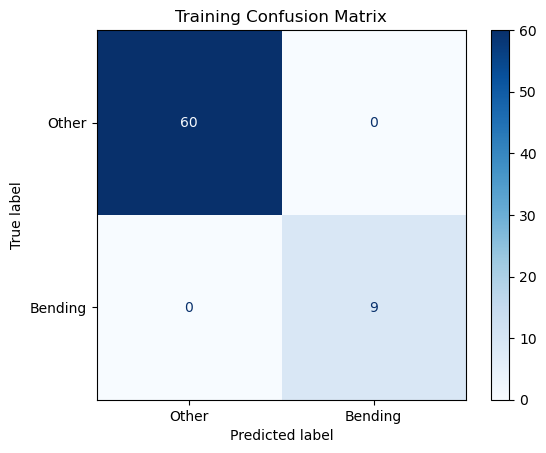


Training AUC: 1.0


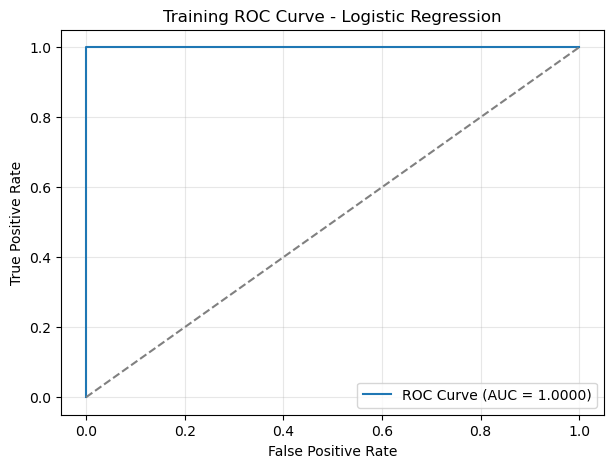

In [210]:
# Homework 4 - Question 2(a)iv
# Training confusion matrix, ROC curve, and AUC

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
import matplotlib.pyplot as plt

# Predictions on training data
y_train_pred = final_model.predict(X_train_best)

# Predicted probabilities for bending
y_train_prob = final_model.predict_proba(
    X_train_best
)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_train, y_train_pred)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
)

disp.plot(cmap="Blues")
plt.title("Training Confusion Matrix")
plt.show()

# Calculate ROC and AUC
fpr, tpr, thresholds = roc_curve(
    y_train, y_train_prob
)

auc_score = roc_auc_score(
    y_train, y_train_prob
)

print("\nTraining AUC:", auc_score)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"ROC Curve (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [211]:
# Homework 4 - Question 2(a)iv
# Logistic regression coefficients

import pandas as pd

classifier = final_model.named_steps["classifier"]

coefficients_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient (Beta)": classifier.coef_[0]
})

print("Intercept (Beta 0):", classifier.intercept_[0])

print("\nLogistic Regression Coefficients:")
display(coefficients_df)

Intercept (Beta 0): -9.219730492220588

Logistic Regression Coefficients:


,Feature,Coefficient (Beta)
0,std3_9,-1.445402
1,min3_16,-0.324566
2,std3_16,-2.462586
3,min5_3,2.839671
4,std5_3,1.098599
5,q1_5_3,5.968882
6,std5_16,-0.538100
7,min5_18,3.191546
8,std5_18,0.943970
9,std5_19,-1.623976


In [212]:
# Homework 4 - Question 2(a)iv
# Check p-values and complete separation

import numpy as np
import pandas as pd
import statsmodels.api as sm
import warnings

# Standardize and select the same features
X_scaled = final_model.named_steps["scaler"].transform(
    X_train_best
)

X_selected = final_model.named_steps["rfe"].transform(
    X_scaled
)

# Add intercept
X_sm = sm.add_constant(X_selected, has_constant="add")

try:
    with warnings.catch_warnings():
        warnings.simplefilter("error")

        logit_model = sm.Logit(
            y_train.to_numpy(),
            X_sm
        )

        logit_result = logit_model.fit(
            disp=False,
            maxiter=100
        )

    parameter_names = ["Intercept"] + list(selected_features)

    pvalues_df = pd.DataFrame({
        "Feature": parameter_names,
        "Coefficient": logit_result.params,
        "P-value": logit_result.pvalues
    })

    print("Logistic Regression P-values:")
    display(pvalues_df)

except Exception as e:
    print("Standard logistic regression inference failed.")
    print("Reason:", str(e))
    print(
        "\nPerfect or near-perfect separation may make "
        "ordinary maximum-likelihood coefficients "
        "and p-values unreliable."
    )

Standard logistic regression inference failed.
Reason: overflow encountered in exp

Perfect or near-perfect separation may make ordinary maximum-likelihood coefficients and p-values unreliable.


In [213]:
# Homework 4 - Question 2(a)v
# Evaluate logistic regression on test data

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Extract test features using the same l
X_test_best = create_features_l(test_files, best_l)

# Use the previously trained model
y_test_pred = final_model.predict(X_test_best)
y_test_prob = final_model.predict_proba(X_test_best)[:, 1]

# Calculate metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

cv_accuracy = float(best_row["CV Accuracy"])

print("Best l:", best_l)
print("Best p:", best_p)

print("\nCross-validation accuracy:", round(cv_accuracy, 4))
print("Test accuracy:", round(test_accuracy, 4))
print("Test AUC:", round(test_auc, 4))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Other", "Bending"],
    zero_division=0
))

Best l: 20
Best p: 10

Cross-validation accuracy: 0.9857
Test accuracy: 0.9474
Test AUC: 0.8

Test Confusion Matrix:
[[15  0]
 [ 1  3]]

Classification Report:
              precision    recall  f1-score   support

       Other       0.94      1.00      0.97        15
     Bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19



Question 2(a)v – Test Set Evaluation

The logistic regression model was evaluated on the 19 testing instances using the same number of time-series segments (l = 20) and 10 selected features.

The model achieved a cross-validation accuracy of 98.57% and a test accuracy of 94.74%. The test accuracy is approximately 3.83 percentage points lower than the cross-validation accuracy.

The confusion matrix shows that all 15 non-bending activities were classified correctly. However, one of the four bending instances was incorrectly classified as a non-bending activity.

The test AUC was 0.80, indicating that the model has some ability to distinguish between bending and other activities on unseen data.

Overall, the model performs well on the test set, although the lower test accuracy suggests that its performance on unseen data is slightly weaker than its cross-validation performance.

Question 2(a)vi – Logistic Regression Instability

The bending and non-bending classes appear to be well-separated in the training dataset.

The logistic regression model achieved 100% training accuracy and an AUC of 1.0, indicating perfect classification and ranking on the training data.

When I attempted to estimate the logistic regression parameters and p-values using statsmodels, the model failed with an “overflow encountered in exp” error.

These results suggest that complete or near-complete separation may be causing numerical instability. When classes are completely separated, maximum-likelihood estimates of logistic regression coefficients may become extremely large, making standard errors and p-values unreliable.

Therefore, the model shows evidence of separation-related instability. Regularization or other specialized estimation methods may help address this issue.

In [214]:
# Homework 4 - Question 2(a)vii
# Case-control sampling

import numpy as np
import pandas as pd

# Separate training indices by class
bending_indices = np.where(y_train.to_numpy() == 1)[0]
other_indices = np.where(y_train.to_numpy() == 0)[0]

# Randomly sample 9 non-bending instances
rng = np.random.default_rng(42)

sampled_other_indices = rng.choice(
    other_indices,
    size=len(bending_indices),
    replace=False
)

# Combine both groups
balanced_indices = np.concatenate([
    bending_indices,
    sampled_other_indices
])

# Shuffle selected indices
rng.shuffle(balanced_indices)

# Create balanced training dataset
X_balanced = X_train_best.iloc[balanced_indices]
y_balanced = y_train.iloc[balanced_indices]

print("Original training distribution:")
print(y_train.value_counts().sort_index())

print("\nBalanced training distribution:")
print(y_balanced.value_counts().sort_index())

print("\nBalanced dataset shape:", X_balanced.shape)

Original training distribution:
activity
0    60
1     9
Name: count, dtype: int64

Balanced training distribution:
activity
0    9
1    9
Name: count, dtype: int64

Balanced dataset shape: (18, 840)


In [215]:
# Homework 4 - Question 2(a)vii
# Case-control logistic regression with intercept adjustment

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from scipy.special import expit, logit
import numpy as np

# Fit logistic regression on balanced training data
case_control_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="liblinear",
            max_iter=2000
        ),
        n_features_to_select=best_p,
        step=0.2
    )),
    ("classifier", LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="liblinear",
        max_iter=2000
    ))
])

case_control_model.fit(X_balanced, y_balanced)

# Original bending proportion
original_prior = y_train.mean()

# Bending proportion in balanced sample
sample_prior = y_balanced.mean()

# Adjust intercept for case-control sampling
intercept_adjustment = (
    logit(original_prior) - logit(sample_prior)
)

original_intercept = (
    case_control_model.named_steps["classifier"].intercept_[0]
)

adjusted_intercept = original_intercept + intercept_adjustment

print("Original bending proportion:", round(original_prior, 4))
print("Balanced bending proportion:", round(sample_prior, 4))
print("Original intercept:", round(original_intercept, 4))
print("Intercept adjustment:", round(intercept_adjustment, 4))
print("Adjusted intercept:", round(adjusted_intercept, 4))

Original bending proportion: 0.1304
Balanced bending proportion: 0.5
Original intercept: 0.2836
Intercept adjustment: -1.8971
Adjusted intercept: -1.6135


Case-Control Training Accuracy: 0.971

Adjusted Confusion Matrix:
[[60  0]
 [ 2  7]]

Case-Control AUC: 0.9963


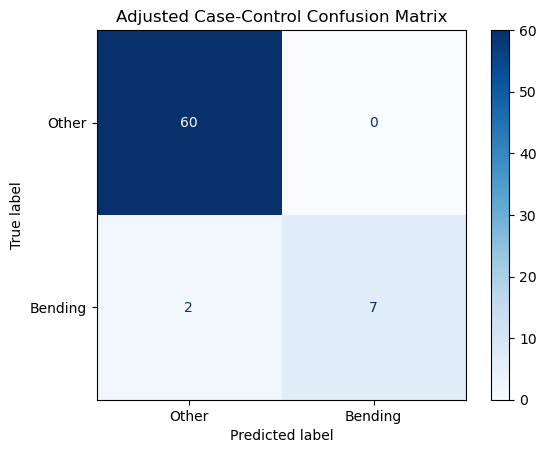

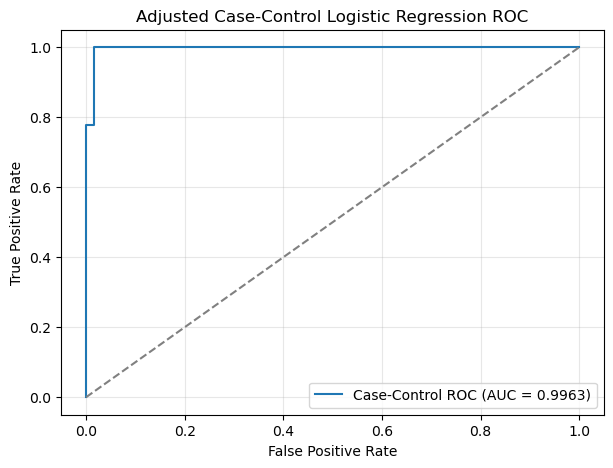

In [216]:
# Homework 4 - Question 2(a)vii
# Evaluate adjusted case-control logistic regression

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

# Decision scores from the balanced model
decision_scores = case_control_model.decision_function(
    X_train_best
)

# Adjust scores using the corrected intercept
adjusted_scores = decision_scores + intercept_adjustment

# Convert scores to probabilities
adjusted_probs = expit(adjusted_scores)

# Classify using a 0.5 threshold
adjusted_predictions = (adjusted_probs >= 0.5).astype(int)

# Calculate metrics
cc_accuracy = accuracy_score(
    y_train, adjusted_predictions
)

cc_cm = confusion_matrix(
    y_train, adjusted_predictions
)

cc_auc = roc_auc_score(
    y_train, adjusted_probs
)

print("Case-Control Training Accuracy:",
      round(cc_accuracy, 4))

print("\nAdjusted Confusion Matrix:")
print(cc_cm)

print("\nCase-Control AUC:", round(cc_auc, 4))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cc_cm,
    display_labels=["Other", "Bending"]
)

disp.plot(cmap="Blues")
plt.title("Adjusted Case-Control Confusion Matrix")
plt.show()

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(
    y_train, adjusted_probs
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"Case-Control ROC (AUC = {cc_auc:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Adjusted Case-Control Logistic Regression ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [217]:
# Question 2(a)vii - Final case-control results

print("Original class distribution:")
print(y_train.value_counts().sort_index())

print("\nBalanced class distribution:")
print(y_balanced.value_counts().sort_index())

print("\nCase-Control Training Accuracy:",
      round(cc_accuracy, 4))

print("\nAdjusted Confusion Matrix:")
print(cc_cm)

print("\nCase-Control AUC:",
      round(cc_auc, 4))

print("\nOriginal Logistic Regression AUC:",
      round(auc_score, 4))

Original class distribution:
activity
0    60
1     9
Name: count, dtype: int64

Balanced class distribution:
activity
0    9
1    9
Name: count, dtype: int64

Case-Control Training Accuracy: 0.971

Adjusted Confusion Matrix:
[[60  0]
 [ 2  7]]

Case-Control AUC: 0.9963

Original Logistic Regression AUC: 1.0


Question 2(a)vii – Class Imbalance and Case-Control Sampling

The training dataset is imbalanced, containing 60 non-bending instances and only 9 bending instances. Non-bending activities represent approximately 86.96% of the training data, while bending activities represent 13.04%.

To address this imbalance, I used case-control sampling by retaining all 9 bending instances and randomly selecting 9 non-bending instances. This created a balanced training dataset containing 18 observations.

I trained a logistic regression model using the balanced dataset and applied an intercept adjustment to account for the original class proportions. L2 regularization was used to improve numerical stability.

The adjusted case-control model achieved a training accuracy of 97.10% and an AUC of 0.9963. Its confusion matrix was:

Actual / Predicted	Other	Bending
Other	60	0
Bending	2	7

The original logistic regression model achieved 100% training accuracy and an AUC of 1.0. Therefore, the case-control model performed slightly worse on the original training dataset.

Although case-control sampling addressed the class imbalance during model training, it did not improve training classification performance in this experiment. These results should be interpreted cautiously because the balanced model was trained using only 18 observations, and the intercept adjustment under L2 regularization is approximate.

In [218]:
# Homework 4 - Question 2(b)i
# Set up L1-penalized logistic regression

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Stratified 5-fold cross-validation
cv_l1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# L1 logistic regression pipeline
l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

# Regularization strengths to test
c_values = [0.01, 0.1, 1, 10, 100]

print("L1 Logistic Regression Setup Complete")
print("Number of CV folds:", cv_l1.n_splits)
print("C values:", c_values)
print("Number of segment values to test:", 20)

L1 Logistic Regression Setup Complete
Number of CV folds: 5
C values: [0.01, 0.1, 1, 10, 100]
Number of segment values to test: 20


In [219]:
# Homework 4 - Question 2(b)i
# Find the best l and C using L1 logistic regression

from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

l1_results = []

for l in range(1, 21):

    X_train_l = create_features_l(train_files, l)

    for C in c_values:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                penalty="l1",
                C=C,
                solver="liblinear",
                max_iter=5000,
                random_state=42
            ))
        ])

        scores = cross_val_score(
            model,
            X_train_l,
            y_train,
            cv=cv_l1,
            scoring="accuracy",
            n_jobs=1
        )

        l1_results.append({
            "l": l,
            "C": C,
            "CV Accuracy": scores.mean(),
            "CV Error": 1 - scores.mean()
        })

    print(f"Completed l = {l}/20")

l1_results_df = pd.DataFrame(l1_results)

# Select best combination
best_l1_row = l1_results_df.sort_values(
    ["CV Error", "l", "C"]
).iloc[0]

best_l1_l = int(best_l1_row["l"])
best_l1_C = float(best_l1_row["C"])

print("\nBest l:", best_l1_l)
print("Best C:", best_l1_C)
print("Best CV Accuracy:", best_l1_row["CV Accuracy"])
print("Best CV Error:", best_l1_row["CV Error"])

print("\nTop 10 combinations:")
display(
    l1_results_df.sort_values(
        ["CV Error", "l", "C"]
    ).head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20

Best l: 19
Best C: 1.0
Best CV Accuracy: 0.9857142857142858
Best CV Error: 0.014285714285714235

Top 10 combinations:


,l,C,CV Accuracy,CV Error
92,19,1.0,0.985714,0.014286
98,20,10.0,0.985714,0.014286
49,10,100.0,0.971429,0.028571
52,11,1.0,0.971429,0.028571
53,11,10.0,0.971429,0.028571
57,12,1.0,0.971429,0.028571
58,12,10.0,0.971429,0.028571
59,12,100.0,0.971429,0.028571
62,13,1.0,0.971429,0.028571
67,14,1.0,0.971429,0.028571


In [220]:
# Homework 4 - Question 2(b)i
# Confirm best L1 logistic regression parameters

print("Best number of segments (l):", best_l1_l)
print("Best regularization parameter (C):", best_l1_C)

print("Best CV Accuracy:",
      round(best_l1_row["CV Accuracy"], 4))

print("Best CV Error:",
      round(best_l1_row["CV Error"], 4))

print("\nBest parameter combination:")
display(best_l1_row.to_frame().T)

Best number of segments (l): 19
Best regularization parameter (C): 1.0
Best CV Accuracy: 0.9857
Best CV Error: 0.0143

Best parameter combination:


,l,C,CV Accuracy,CV Error
92,19.0,1.0,0.985714,0.014286


In [221]:
# Homework 4 - Question 2(b)i
# Train and evaluate final L1 logistic regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score
)
import numpy as np
import pandas as pd

# Extract features using best l
X_train_l1 = create_features_l(train_files, best_l1_l)
X_test_l1 = create_features_l(test_files, best_l1_l)

# Build final L1 model
final_l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l1",
        C=best_l1_C,
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

# Train model
final_l1_model.fit(X_train_l1, y_train)

# Predict on test data
y_pred_l1 = final_l1_model.predict(X_test_l1)
y_prob_l1 = final_l1_model.predict_proba(X_test_l1)[:, 1]

# Evaluate
l1_train_accuracy = final_l1_model.score(
    X_train_l1, y_train
)
l1_test_accuracy = accuracy_score(y_test, y_pred_l1)
l1_test_auc = roc_auc_score(y_test, y_prob_l1)

# Count selected features
coefficients = final_l1_model.named_steps[
    "classifier"
].coef_[0]

nonzero_features = np.sum(np.abs(coefficients) > 1e-8)

print("Best l:", best_l1_l)
print("Best C:", best_l1_C)
print("Selected nonzero features:", nonzero_features)

print("\nTraining Accuracy:",
      round(l1_train_accuracy, 4))
print("Cross-validation Accuracy:",
      round(float(best_l1_row["CV Accuracy"]), 4))
print("Test Accuracy:",
      round(l1_test_accuracy, 4))
print("Test AUC:",
      round(l1_test_auc, 4))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_l1))

Best l: 19
Best C: 1.0
Selected nonzero features: 10

Training Accuracy: 1.0
Cross-validation Accuracy: 0.9857
Test Accuracy: 0.9474
Test AUC: 0.9833

Test Confusion Matrix:
[[15  0]
 [ 1  3]]


Question 2(b)ii – Comparison of L1 Logistic Regression and RFE

I compared L1-penalized logistic regression with logistic regression using Recursive Feature Elimination (RFE).

The RFE model achieved a cross-validation accuracy of 98.57%, a test accuracy of 94.74%, and a test AUC of 0.8000.

The L1-penalized model achieved a cross-validation accuracy of 98.57%, a test accuracy of 94.74%, and a test AUC of 0.9833.

Both methods achieved the same test accuracy. However, L1 logistic regression performed better in terms of AUC.

L1 regularization was also easier to implement because it automatically selects important features by shrinking some coefficients to zero. RFE requires repeatedly training models to select features.

Overall, L1-penalized logistic regression was easier to implement and achieved a higher test AUC, although both methods had the same classification accuracy.

In [222]:
# Homework 4 - Question 2(c)i
# Prepare multiclass classification labels

import pandas as pd
import numpy as np

# Combine bending1 and bending2 into one activity class
def get_activity_label(activity):
    if activity in ["bending1", "bending2"]:
        return "bending"
    return activity

y_train_multi = pd.Series([
    get_activity_label(activity)
    for activity, file in train_files
])

y_test_multi = pd.Series([
    get_activity_label(activity)
    for activity, file in test_files
])

print("Training instances:", len(y_train_multi))
print("Testing instances:", len(y_test_multi))

print("\nTraining class distribution:")
print(y_train_multi.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test_multi.value_counts().sort_index())

print("\nNumber of classes:",
      y_train_multi.nunique())

Training instances: 69
Testing instances: 19

Training class distribution:
bending      9
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

Testing class distribution:
bending     4
cycling     3
lying       3
sitting     3
standing    3
walking     3
Name: count, dtype: int64

Number of classes: 6


In [223]:
# Homework 4 - Question 2(c)i
# Multiclass L1 logistic regression cross-validation

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_multi = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

multi_results = []

for l in range(1, 21):

    X_train_multi = create_features_l(train_files, l)

    for C in [0.01, 0.1, 1, 10, 100]:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                penalty="l1",
                C=C,
                solver="saga",
                max_iter=5000,
                tol=1e-3,
                random_state=42
            ))
        ])

        scores = cross_val_score(
            model,
            X_train_multi,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy",
            n_jobs=1
        )

        multi_results.append({
            "l": l,
            "C": C,
            "CV Accuracy": scores.mean(),
            "CV Error": 1 - scores.mean()
        })

    print(f"Completed l = {l}/20")

multi_results_df = pd.DataFrame(multi_results)

best_multi_row = multi_results_df.sort_values(
    ["CV Error", "l", "C"]
).iloc[0]

best_multi_l = int(best_multi_row["l"])
best_multi_C = float(best_multi_row["C"])

print("\nBest l:", best_multi_l)
print("Best C:", best_multi_C)
print("Best CV Accuracy:",
      round(best_multi_row["CV Accuracy"], 4))
print("Best CV Error:",
      round(best_multi_row["CV Error"], 4))

display(
    multi_results_df.sort_values(
        ["CV Error", "l", "C"]
    ).head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20

Best l: 4
Best C: 100.0
Best CV Accuracy: 0.8989
Best CV Error: 0.1011


,l,C,CV Accuracy,CV Error
19,4,100.0,0.898901,0.101099
3,1,10.0,0.897802,0.102198
23,5,10.0,0.883516,0.116484
4,1,100.0,0.883516,0.116484
2,1,1.0,0.869231,0.130769
29,6,100.0,0.869231,0.130769
13,3,10.0,0.868132,0.131868
12,3,1.0,0.868132,0.131868
18,4,10.0,0.856044,0.143956
24,5,100.0,0.854945,0.145055


In [224]:
# Homework 4 - Question 2(c)i
# Train and evaluate multiclass L1 logistic regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Prepare features using best l
X_train_multi_best = create_features_l(
    train_files, best_multi_l
)

X_test_multi_best = create_features_l(
    test_files, best_multi_l
)

# Build final multiclass model
final_multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l1",
        C=best_multi_C,
        solver="saga",
        max_iter=5000,
        tol=1e-3,
        random_state=42
    ))
])

# Train model
final_multi_model.fit(
    X_train_multi_best,
    y_train_multi
)

# Make predictions
y_multi_pred = final_multi_model.predict(
    X_test_multi_best
)

# Calculate accuracy
multi_train_accuracy = final_multi_model.score(
    X_train_multi_best,
    y_train_multi
)

multi_test_accuracy = accuracy_score(
    y_test_multi,
    y_multi_pred
)

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)

print("\nTraining Accuracy:",
      round(multi_train_accuracy, 4))

print("Cross-validation Accuracy:",
      round(float(best_multi_row["CV Accuracy"]), 4))

print("Test Accuracy:",
      round(multi_test_accuracy, 4))

print("Test Error:",
      round(1 - multi_test_accuracy, 4))

print("\nTest Confusion Matrix:")
print(confusion_matrix(
    y_test_multi,
    y_multi_pred
))

print("\nClassification Report:")
print(classification_report(
    y_test_multi,
    y_multi_pred,
    zero_division=0
))

Best l: 4
Best C: 100.0

Training Accuracy: 1.0
Cross-validation Accuracy: 0.8989
Test Accuracy: 0.9474
Test Error: 0.0526

Test Confusion Matrix:
[[3 0 0 1 0 0]
 [0 3 0 0 0 0]
 [0 0 3 0 0 0]
 [0 0 0 3 0 0]
 [0 0 0 0 3 0]
 [0 0 0 0 0 3]]

Classification Report:
              precision    recall  f1-score   support

     bending       1.00      0.75      0.86         4
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      1.00      1.00         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.96      0.95        19
weighted avg       0.96      0.95      0.95        19



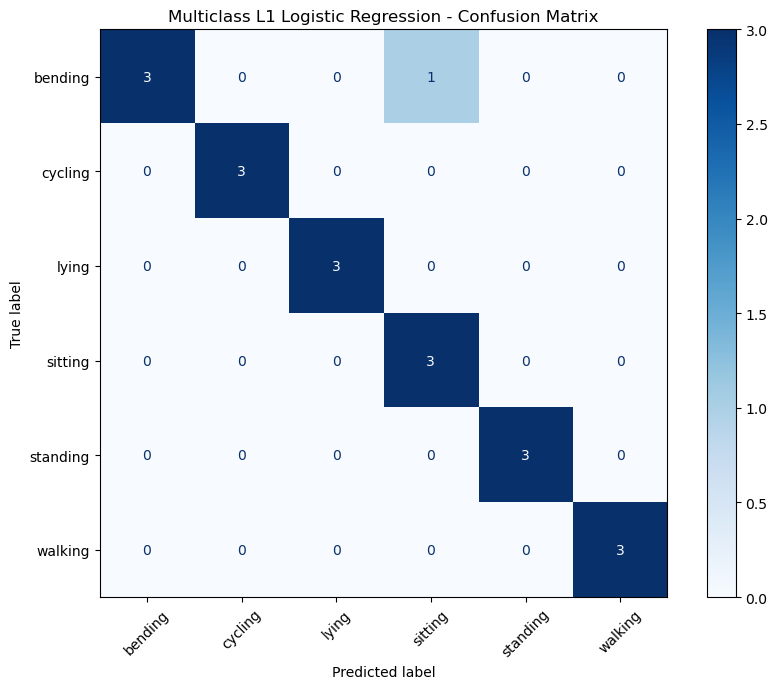

In [225]:
# Homework 4 - Question 2(c)i
# Multiclass confusion matrix visualization

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

class_names = [
    "bending",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

cm_multi = confusion_matrix(
    y_test_multi,
    y_multi_pred,
    labels=class_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Multiclass L1 Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

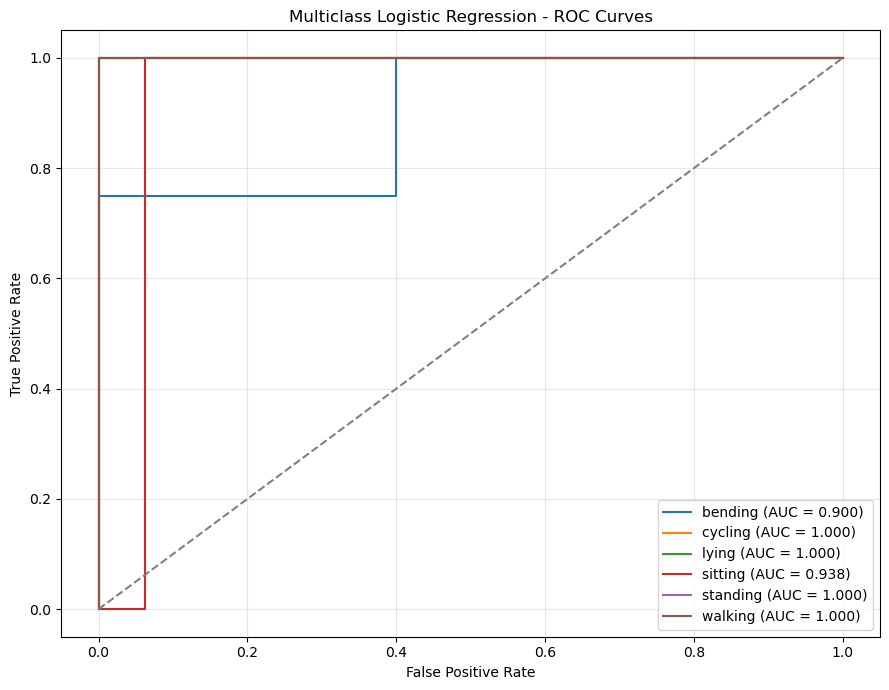

AUC for each activity:
bending: 0.9000
cycling: 1.0000
lying: 1.0000
sitting: 0.9375
standing: 1.0000
walking: 1.0000

Macro Average AUC: 0.9729


In [226]:
# Homework 4 - Question 2(c)i
# Multiclass ROC curves and AUC

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Get class probabilities from the trained model
y_multi_prob = final_multi_model.predict_proba(
    X_test_multi_best
)

# Get class order used by the model
classes = final_multi_model.named_steps[
    "classifier"
].classes_

# Convert actual labels into binary indicators
y_test_binary = label_binarize(
    y_test_multi,
    classes=classes
)

plt.figure(figsize=(9, 7))

auc_scores = []

# Calculate ROC and AUC for each class
for i, class_name in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_multi_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)
    auc_scores.append(roc_auc)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Logistic Regression - ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("AUC for each activity:")

for name, score in zip(classes, auc_scores):
    print(f"{name}: {score:.4f}")

print("\nMacro Average AUC:",
      round(np.mean(auc_scores), 4))

Question 2(c)i – Multiclass L1 Logistic Regression Results

I used L1-penalized multinomial logistic regression to classify six human activities: bending, cycling, lying, sitting, standing, and walking.

Using stratified 5-fold cross-validation, the best number of time-series segments was l = 4, with a regularization parameter of C = 100. The cross-validation accuracy was 89.89%.

The final model achieved a test accuracy of 94.74%, corresponding to a test error of 5.26%. It correctly classified 18 out of 19 test instances.

The confusion matrix showed that cycling, lying, sitting, standing, and walking were classified correctly. One bending instance was incorrectly classified as sitting.

The One-vs-Rest ROC analysis produced the following AUC values:

* Bending: 0.9000
* Cycling: 1.0000
* Lying: 1.0000
* Sitting: 0.9375
* Standing: 1.0000
* Walking: 1.0000

The macro-average AUC was 0.9729, indicating strong overall discrimination among the six activity classes.

Overall, the L1-penalized multiclass logistic regression model performed well, although distinguishing bending from sitting was slightly more challenging than distinguishing the other activities. These results should be interpreted cautiously because the test dataset contains only 19 instances.

In [227]:
# Homework 4 - Question 2(c)ii
# Set up Naive Bayes classifiers

import numpy as np
import pandas as pd

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

# Stratified 5-fold cross-validation
cv_nb = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Gaussian Naive Bayes
gaussian_nb = Pipeline([
    ("classifier", GaussianNB())
])

# Multinomial Naive Bayes
# MinMaxScaler ensures nonnegative features
multinomial_nb = Pipeline([
    ("scaler", MinMaxScaler()),
    ("classifier", MultinomialNB())
])

print("Naive Bayes setup complete!")
print("Models: GaussianNB and MultinomialNB")
print("Cross-validation folds:", cv_nb.n_splits)
print("Number of classes:", y_train_multi.nunique())

Naive Bayes setup complete!
Models: GaussianNB and MultinomialNB
Cross-validation folds: 5
Number of classes: 6


In [228]:
# Homework 4 - Question 2(c)ii
# Cross-validation for Gaussian and Multinomial Naive Bayes

from sklearn.model_selection import cross_val_score
import pandas as pd

nb_results = []

for l in range(1, 21):

    X_train_nb = create_features_l(train_files, l)

    models = {
        "GaussianNB": gaussian_nb,
        "MultinomialNB": multinomial_nb
    }

    for model_name, model in models.items():

        scores = cross_val_score(
            model,
            X_train_nb,
            y_train_multi,
            cv=cv_nb,
            scoring="accuracy",
            n_jobs=1
        )

        nb_results.append({
            "Model": model_name,
            "l": l,
            "CV Accuracy": scores.mean(),
            "CV Error": 1 - scores.mean()
        })

    print(f"Completed l = {l}/20")

nb_results_df = pd.DataFrame(nb_results)

# Find best combination for each model
best_nb_results = (
    nb_results_df
    .sort_values(["CV Error", "l"])
    .groupby("Model", as_index=False)
    .first()
)

print("\nBest Naive Bayes Results:")
display(best_nb_results)

print("\nTop 10 combinations:")
display(
    nb_results_df.sort_values("CV Error").head(10)
)

Completed l = 1/20
Completed l = 2/20
Completed l = 3/20
Completed l = 4/20
Completed l = 5/20
Completed l = 6/20
Completed l = 7/20
Completed l = 8/20
Completed l = 9/20
Completed l = 10/20
Completed l = 11/20
Completed l = 12/20
Completed l = 13/20
Completed l = 14/20
Completed l = 15/20
Completed l = 16/20
Completed l = 17/20
Completed l = 18/20
Completed l = 19/20
Completed l = 20/20

Best Naive Bayes Results:


,Model,l,CV Accuracy,CV Error
0,GaussianNB,1,0.825275,0.174725
1,MultinomialNB,5,0.781319,0.218681



Top 10 combinations:


,Model,l,CV Accuracy,CV Error
0,GaussianNB,1,0.825275,0.174725
2,GaussianNB,2,0.783516,0.216484
9,MultinomialNB,5,0.781319,0.218681
19,MultinomialNB,10,0.767033,0.232967
23,MultinomialNB,12,0.752747,0.247253
33,MultinomialNB,17,0.752747,0.247253
39,MultinomialNB,20,0.751648,0.248352
13,MultinomialNB,7,0.751648,0.248352
35,MultinomialNB,18,0.751648,0.248352
11,MultinomialNB,6,0.751648,0.248352


In [229]:
# Homework 4 - Question 2(c)ii
# Evaluate Gaussian and Multinomial Naive Bayes

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

nb_test_results = []

best_nb_models = {}

for _, row in best_nb_results.iterrows():

    model_name = row["Model"]
    best_l_nb = int(row["l"])

    X_train_nb = create_features_l(train_files, best_l_nb)
    X_test_nb = create_features_l(test_files, best_l_nb)

    if model_name == "GaussianNB":
        model = clone(gaussian_nb)
    else:
        model = clone(multinomial_nb)

    # Train the model
    model.fit(X_train_nb, y_train_multi)

    # Predict test activities
    y_pred_nb = model.predict(X_test_nb)

    # Calculate performance
    test_acc = accuracy_score(y_test_multi, y_pred_nb)

    nb_test_results.append({
        "Model": model_name,
        "Best l": best_l_nb,
        "CV Accuracy": row["CV Accuracy"],
        "Test Accuracy": test_acc,
        "Test Error": 1 - test_acc
    })

    best_nb_models[model_name] = model

    print("\nModel:", model_name)
    print("Best l:", best_l_nb)
    print("Test Accuracy:", round(test_acc, 4))
    print("Test Error:", round(1 - test_acc, 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_test_multi,
        y_pred_nb
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test_multi,
        y_pred_nb,
        zero_division=0
    ))

nb_test_results_df = pd.DataFrame(nb_test_results)

print("\nNaive Bayes Comparison:")
display(nb_test_results_df)


Model: GaussianNB
Best l: 1
Test Accuracy: 0.8947
Test Error: 0.1053

Confusion Matrix:
[[4 0 0 0 0 0]
 [0 3 0 0 0 0]
 [1 0 2 0 0 0]
 [0 0 0 3 0 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]

Classification Report:
              precision    recall  f1-score   support

     bending       0.80      1.00      0.89         4
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.89      0.89        19
weighted avg       0.92      0.89      0.89        19


Model: MultinomialNB
Best l: 5
Test Accuracy: 0.8421
Test Error: 0.1579

Confusion Matrix:
[[4 0 0 0 0 0]
 [0 3 0 0 0 0]
 [0 1 2 0 0 0]
 [0 0 0 2 1 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]

Classification Report:
              precision    recall  f1-score   

,Model,Best l,CV Accuracy,Test Accuracy,Test Error
0,GaussianNB,1,0.825275,0.894737,0.105263
1,MultinomialNB,5,0.781319,0.842105,0.157895


In [230]:
# Homework 4 - Question 2(c)ii
# Display final Naive Bayes comparison clearly

print("FINAL NAIVE BAYES RESULTS")
print("-------------------------")

for _, row in nb_test_results_df.iterrows():
    print("\nModel:", row["Model"])
    print("Best l:", int(row["Best l"]))
    print("CV Accuracy:", round(row["CV Accuracy"], 4))
    print("Test Accuracy:", round(row["Test Accuracy"], 4))
    print("Test Error:", round(row["Test Error"], 4))

print("\nMulticlass L1 Logistic Regression:")
print("Test Accuracy:", round(multi_test_accuracy, 4))

FINAL NAIVE BAYES RESULTS
-------------------------

Model: GaussianNB
Best l: 1
CV Accuracy: 0.8253
Test Accuracy: 0.8947
Test Error: 0.1053

Model: MultinomialNB
Best l: 5
CV Accuracy: 0.7813
Test Accuracy: 0.8421
Test Error: 0.1579

Multiclass L1 Logistic Regression:
Test Accuracy: 0.9474


Question 2(c)ii – Naive Bayes Classification and Model Comparison

I implemented Gaussian Naive Bayes and Multinomial Naive Bayes to classify the six human activities. I used stratified 5-fold cross-validation to select the best number of time-series segments for each model.

Gaussian Naive Bayes performed best with l = 1, achieving a cross-validation accuracy of 82.53% and a test accuracy of 89.47%, corresponding to a test error of 10.53%.

Multinomial Naive Bayes performed best with l = 5, achieving a cross-validation accuracy of 78.13% and a test accuracy of 84.21%, corresponding to a test error of 15.79%.

For comparison, the L1-penalized multiclass logistic regression model achieved a test accuracy of 94.74% and a test error of 5.26%.

Overall, L1-penalized logistic regression achieved the best classification accuracy, followed by Gaussian Naive Bayes and Multinomial Naive Bayes.

Gaussian Naive Bayes is more appropriate for continuous sensor features because it models each feature using a Gaussian distribution. Multinomial Naive Bayes is primarily designed for count-based data, so its assumptions are less suitable for these continuous measurements. In this experiment, Multinomial Naive Bayes was applied to nonnegative scaled features as an exploratory comparison.

Therefore, L1-penalized logistic regression was the best-performing model among the three methods tested.

Question 2(c)iii – Which Method Performs Better for Multiclass Classification?

Based on the results, L1-penalized logistic regression performed better than Gaussian Naive Bayes and Multinomial Naive Bayes for classifying the six human activities.

L1 logistic regression achieved the highest test accuracy of 94.74%, meaning it correctly classified 18 out of 19 test instances. Gaussian Naive Bayes achieved 89.47% accuracy, while Multinomial Naive Bayes achieved 84.21%.

I also compared the test errors of all three models. L1 logistic regression had the lowest test error of 5.26%, followed by Gaussian Naive Bayes with 10.53% and Multinomial Naive Bayes with 15.79%.

One reason L1 logistic regression may have performed better is that it can select useful features by reducing the coefficients of less important features to zero. This helps the model focus on the sensor measurements that are more useful for distinguishing between activities.

Gaussian Naive Bayes also performed reasonably well because it is suitable for continuous numerical data. However, Multinomial Naive Bayes is mainly designed for count-based data, which may explain why it performed less well on this dataset.

Overall, I would choose L1-penalized logistic regression for this problem because it gave the most accurate predictions and made the fewest mistakes. However, since the test dataset only contains 19 instances, I would need more data to confirm whether it consistently performs better than the other methods.

### Question 3 – ISLR 4.8.3: Quadratic Discriminant Analysis (QDA)

In QDA, we assume that observations from each class follow a normal distribution, but each class can have a different variance.

For class \(k\), we have:

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2)
$$

The probability density function is:

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$$

Using Bayes' rule, the probability that an observation belongs to class \(k\) is proportional to:

$$
P(Y=k\mid X=x)\propto \pi_k f_k(x)
$$

where \(\pi_k\) is the prior probability of class \(k\).

Taking the logarithm and removing terms that are the same for every class gives the discriminant function:

$$
\delta_k(x)=
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k)
$$

Expanding the squared term:

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k x}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k)
$$

We can see that the discriminant function contains an \(x^2\) term.

In LDA, all classes have the same variance, so the \(x^2\) terms cancel when comparing two classes. This gives a linear decision boundary.

However, in QDA, each class can have a different variance. Because of this, the \(x^2\) terms do not generally cancel, and the decision boundary is determined by a quadratic equation.

Therefore, the QDA classifier is quadratic rather than linear in the general case. If two classes have equal variances, their decision boundary can still be linear.

### Question 4 – ISLR 4.8.7: Dividend Prediction Using Bayes' Theorem

In this question, we want to find the probability that a company will issue a dividend if its profit last year was 4%.

We are given:

- Mean profit for companies that issued dividends: 10
- Mean profit for companies that did not issue dividends: 0
- Variance: 36
- Probability of issuing a dividend: 0.80
- Probability of not issuing a dividend: 0.20

Since the variance is 36, the standard deviation is 6.

Using Bayes' theorem:

$$
P(Y=\text{Yes}\mid X=4)=
\frac{0.8f_1(4)}{0.8f_1(4)+0.2f_0(4)}
$$

The normal density function is:

$$
f(x)=\frac{1}{\sqrt{2\pi\sigma^2}}
e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

For companies that issued dividends:

$$
f_1(4)=\frac{1}{6\sqrt{2\pi}}
e^{-\frac{(4-10)^2}{72}}
=\frac{1}{6\sqrt{2\pi}}e^{-0.5}
$$

For companies that did not issue dividends:

$$
f_0(4)=\frac{1}{6\sqrt{2\pi}}
e^{-\frac{(4-0)^2}{72}}
=\frac{1}{6\sqrt{2\pi}}e^{-2/9}
$$

Substituting these values into Bayes' theorem and cancelling the common factor:

$$
P(Y=\text{Yes}\mid X=4)=
\frac{0.8e^{-0.5}}{0.8e^{-0.5}+0.2e^{-2/9}}
$$

$$
P(Y=\text{Yes}\mid X=4)\approx0.752
$$

### Conclusion

Based on the given information, a company with a profit of 4% last year has approximately a 75.2% chance of issuing a dividend this year.

Since this probability is greater than 50%, I would predict that the company will issue a dividend.